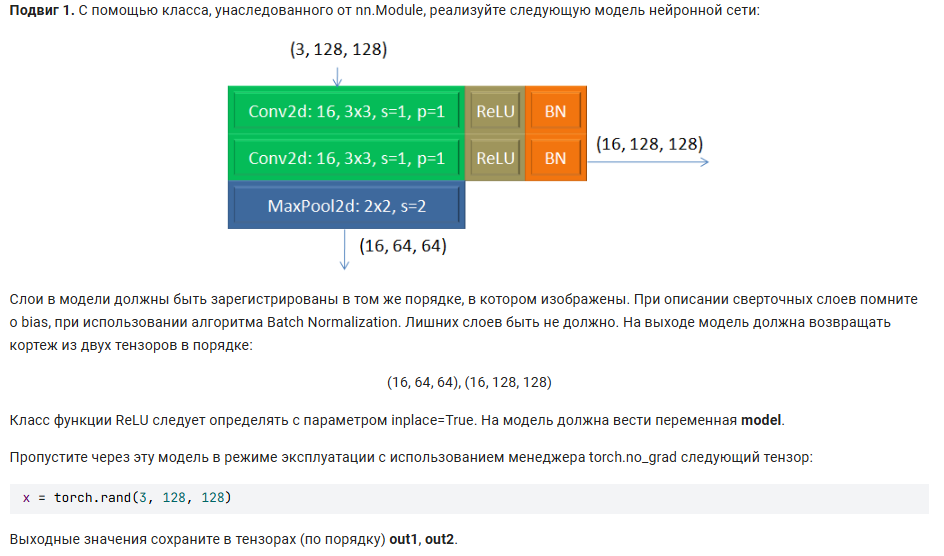

In [9]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели (обязательно до тензора x)

x = torch.rand(3, 128, 128) # тензор x в программе не менять

# здесь продолжайте программу
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(16),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(16)
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.model(x)
        y = self.pool(x)
        return y, x
    
model = MyModel()
model.eval()
with torch.no_grad():
    out1, out2 = model(x.unsqueeze(0))
    
print(out1.shape, out2.shape)

torch.Size([1, 16, 64, 64]) torch.Size([1, 16, 128, 128])


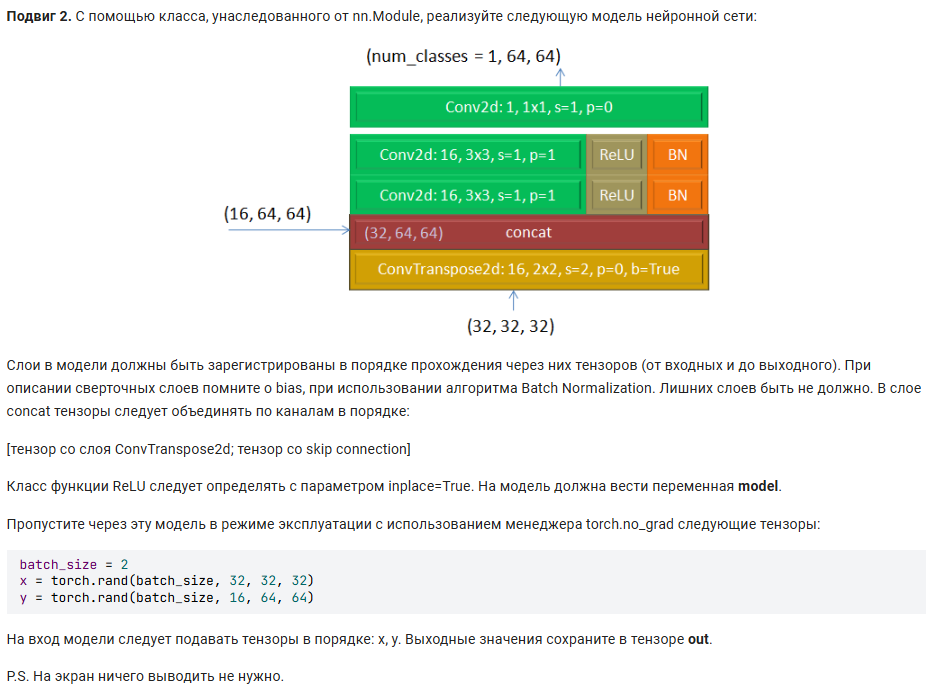

In [18]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели (обязательно до тензоров)
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.ct = nn.ConvTranspose2d(32, 16, 2, 2, 0, bias=True)
        
        self.model = nn.Sequential(
            nn.Conv2d(32, 16, 3, 1, 1, bias=False), 
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(16),
            nn.Conv2d(16, 16, 3, 1, 1, bias=False), 
            nn.ReLU(inplace=True),
            nn.BatchNorm2d(16),
            nn.Conv2d(16, 1, 1, 1, 0, bias=True)
        )

    def forward(self, x, skip):
        concat = torch.cat([self.ct(x), skip], dim=1)
        return self.model(concat)

# тензоры x, y в программе не менять
batch_size = 2
x = torch.rand(batch_size, 32, 32, 32)
y = torch.rand(batch_size, 16, 64, 64)

# здесь продолжайте программу
model = MyModel()
model.eval()
with torch.no_grad():
    out = model(x, y)